# E3：ImageWoof における実時間の比較

`programs/analysis_e3.py` を呼び出し，集計結果（表と図）を表示する．論文用の条件は `analysis_e3.PAPER_CONDITIONS` で指定する（NFG-SVRG は restart，`実験計画.md` 5.6節）．

In [1]:
import os
import sys

sys.path.insert(0, os.path.join(os.getcwd(), "programs"))
import analysis_e3 as a

# 論文用の各手法の条件（必要に応じて変更する）
print(a.PAPER_CONDITIONS)
text = a.write_summary()

{'SGD': ('SGD', 'inner_none_lr0.001_bs128_lambda0.0005_epochs200'), 'SVRG': ('SVRG', 'inner_last_iterate_lr0.001_bs128_lambda0.0005_epochs67'), 'NFG_SVRG': ('NFG_SVRG', 'inner_snapshot_lr0.001_bs128_lambda0.0005_epochs100'), 'ASAI_SVRG': ('ASAI_SVRG', 'inner_last_iterate_lr0.001_bs128_lambda0.0005_epochs100')}


## 集計表（outputs/e3_summary.md）

In [2]:
from IPython.display import Markdown, display

display(Markdown(text))

# E3：ImageWoof における実時間の比較（集計結果）

値はシードの平均 ± 標準誤差である．実時間 $ t $ は time_optimizer + time_svrg_full_grad であり，近似誤差の診断（time_diagnostic）と評価（time_evaluation）の時間は含めない．全ての試行は逐次に1つずつ実行した．

## 時間の表

| 手法 | シード数 | エポック数 | 最終の $ \#\mathrm{grad}/N $ | time_optimizer／エポック［s］ | time_svrg_full_grad／エポック［s］ | t／エポック［s］ | time_diagnostic／エポック［s］（参考） | time_evaluation／エポック［s］（参考） | 最終の t［s］ | 精度40%到達の t［s］（到達数） | 最終の学習損失 | 最終のテスト精度 |
|---|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|
| SGD | 5 | 200 | 200.0 | 6.020 ± 0.060 | 0.000 ± 0.000 | 6.020 ± 0.060 | 0.000 ± 0.000 | 5.867 ± 0.060 | 1203.9 ± 12.0 | 510.6 ± 10.7（5/5） | 3.1407 ± 0.0252 | 0.4654 ± 0.0099 |
| SVRG | 5 | 67 | 202.0 | 10.583 ± 0.089 | 7.378 ± 0.064 | 17.961 ± 0.153 | 0.000 ± 0.000 | 1.779 ± 0.014 | 1211.7 ± 10.3 | 1165.7 ± 18.8（3/5） | 3.6119 ± 0.0154 | 0.3885 ± 0.0064 |
| NFG-SVRG | 5 | 100 | 200.0 | 10.573 ± 0.050 | 0.000 ± 0.000 | 10.573 ± 0.050 | 7.289 ± 0.032 | 1.758 ± 0.008 | 1057.3 ± 5.0 | —（0/5） | 3.8433 ± 0.0350 | 0.3041 ± 0.0120 |
| ASA-SVRG | 5 | 100 | 200.0 | 10.684 ± 0.124 | 0.000 ± 0.000 | 10.684 ± 0.124 | 7.292 ± 0.087 | 1.755 ± 0.020 | 1068.4 ± 12.4 | 661.1 ± 9.6（5/5） | 3.3870 ± 0.0036 | 0.4570 ± 0.0020 |

## 比（実験計画5.5節）

- SVRG の1エポックあたりの時間のうち，全勾配の計算を除いた部分（time_optimizer）：10.583 s．全勾配の計算：7.378 s（1エポックあたりの t の 41.1%）．
- NFG-SVRG の time_optimizer／SVRG の time_optimizer：0.999．
- ASA-SVRG の time_optimizer／SVRG の time_optimizer：1.010．
- ASA-SVRG の time_optimizer／NFG-SVRG の time_optimizer：1.011（平均パラメータの逐次更新のオーバーヘッド 111.8 ms／エポック）．
- SGD の time_optimizer／ASA-SVRG の time_optimizer：0.563．

## 計算機の速度の変化を除いた比

同じ計算でも，試行によって計算機の速度が数%異なる場合がある（下の試行ごとの表を参照）．そのため，各試行の time_optimizer を同じ試行の全勾配の計算の時間で割った比でも比較する．

- time_optimizer／全勾配の計算（試行ごとの比の平均）：SVRG 1.4345，NFG-SVRG 1.4504，ASA-SVRG 1.4653．
- NFG-SVRG／SVRG：1.0111．ASA-SVRG／SVRG：1.0215．
- ASA-SVRG／NFG-SVRG：1.0103（平均パラメータの逐次更新のオーバーヘッド 1.03%）．
- SGD／ASA-SVRG の time_optimizer（同じシードの比）：中央値 0.556（範囲 0.549〜0.602）．

### 試行ごとの1エポックあたりの時間

| シード | SVRG time_optimizer［s］ | SVRG 全勾配［s］ | SVRG 比 | NFG-SVRG time_optimizer［s］ | NFG-SVRG 全勾配［s］ | NFG-SVRG 比 | ASA-SVRG time_optimizer［s］ | ASA-SVRG 全勾配［s］ | ASA-SVRG 比 | SGD time_optimizer［s］ |
|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|
| 0 | 10.361 | 7.225 | 1.4340 | 10.448 | 7.220 | 1.4470 | 10.668 | 7.276 | 1.4663 | 5.858 |
| 1 | 10.491 | 7.303 | 1.4365 | 10.752 | 7.411 | 1.4507 | 10.662 | 7.257 | 1.4691 | 5.961 |
| 2 | 10.480 | 7.300 | 1.4357 | 10.553 | 7.284 | 1.4488 | 10.791 | 7.361 | 1.4661 | 5.963 |
| 3 | 10.770 | 7.503 | 1.4354 | 10.541 | 7.261 | 1.4518 | 11.032 | 7.551 | 1.4611 | 6.133 |
| 4 | 10.814 | 7.558 | 1.4308 | 10.569 | 7.270 | 1.4538 | 10.269 | 7.014 | 1.4641 | 6.181 |

## NFG-SVRG の restart での再計測の確認（実験計画5.6節）

NFG-SVRG は restart（`inner_start="snapshot"`）の結果を上の表と図に用いた．当初の continue （`last_iterate`）の計測は，この節と確認用の図（`e3_check_*.png`）にのみ用いる．

### 計算機の速度の変動（確認2）

- time_optimizer／エポック：restart 10.573 ± 0.050 s，continue 10.708 ± 0.086 s（当初の報告値 10.708 s）．
- restart／continue：0.9874（差 -1.26%）．判定（差が3%以内）：以内．SGD・SVRG・ASA-SVRG の計測をそのまま用いる．
- time_optimizer／全勾配の計算：restart 1.4504 ± 0.0012，continue 1.4478 ± 0.0011（比 1.0018）．

### E0 のログとの一致（確認1）

| シード | 比較した点数 | epoch | oracle_calls | train_loss | test_accuracy | test_correct | approx_error |
|---:|---:|---|---|---|---|---|---|
| 0 | 101 | 完全一致 | 完全一致 | 完全一致 | 完全一致 | 完全一致 | 完全一致 |
| 1 | 101 | 完全一致 | 完全一致 | 完全一致 | 完全一致 | 完全一致 | 完全一致 |
| 2 | 101 | 完全一致 | 完全一致 | 完全一致 | 完全一致 | 完全一致 | 完全一致 |
| 3 | 101 | 完全一致 | 完全一致 | 完全一致 | 完全一致 | 完全一致 | 完全一致 |
| 4 | 101 | 完全一致 | 完全一致 | 完全一致 | 完全一致 | 完全一致 | 完全一致 |

### 計測環境（確認3）

- restart の NFG-SVRG と当初の計測の計測環境（機器，ソフトウェアのバージョン等）は同一である．

### restart と continue の対応のある差（参考）

| シード | 学習損失 restart | 学習損失 continue | 差（restart − continue） | テスト精度 restart | テスト精度 continue | 差（restart − continue） | 精度40%到達の t［s］ restart | continue |
|---:|---:|---:|---:|---:|---:|---:|---:|---:|
| 0 | 3.9744 | 4.0915 | -0.1171 | 0.2616 | 0.1922 | +0.0695 | 到達せず | 到達せず |
| 1 | 3.8140 | 4.0377 | -0.2237 | 0.3138 | 0.2275 | +0.0863 | 到達せず | 到達せず |
| 2 | 3.7741 | 3.8216 | -0.0474 | 0.3332 | 0.2960 | +0.0372 | 到達せず | 到達せず |
| 3 | 3.8036 | 3.7166 | +0.0870 | 0.3143 | 0.3426 | -0.0283 | 到達せず | 到達せず |
| 4 | 3.8504 | 3.9045 | -0.0540 | 0.2978 | 0.2726 | +0.0252 | 到達せず | 到達せず |
| 平均 ± 標準誤差 | | | -0.0710 ± 0.0506 | | | 0.0380 ± 0.0198 | | |

## 計測環境

| 項目 | 値 |
|---|---|
| cpu | Intel(R) Xeon(R) w7-3565X |
| cuda | 12.8 |
| cudnn | 91900 |
| cudnn_benchmark | False |
| cudnn_deterministic | True |
| dataloader_num_workers | 0 |
| deterministic_algorithms | True |
| gpu | NVIDIA RTX PRO 6000 Blackwell Max-Q Workstation Edition |
| gpu_memory_gib | 95.6 |
| logical_cpus | 64 |
| memory_gib | 125.5 |
| pillow | 13.0.0 |
| platform | Linux-6.18.33.2-microsoft-standard-WSL2-x86_64-with-glibc2.35 |
| python | 3.12.15 |
| torch | 2.11.0+cu128 |
| torch_num_threads | 1 |
| torchvision | 0.26.0+cu128 |

全ての試行で計測環境が同一：はい

## 図

- `ex009_e3_imagewoof_walltime/figures/e3_walltime_train_loss.png`
- `ex009_e3_imagewoof_walltime/figures/e3_walltime_test_accuracy.png`
- `ex009_e3_imagewoof_walltime/figures/e3_grad_train_loss.png`
- `ex009_e3_imagewoof_walltime/figures/e3_grad_test_accuracy.png`
- `ex009_e3_imagewoof_walltime/figures/e3_check_walltime_train_loss.png`
- `ex009_e3_imagewoof_walltime/figures/e3_check_walltime_test_accuracy.png`
- `ex009_e3_imagewoof_walltime/figures/e3_check_grad_train_loss.png`
- `ex009_e3_imagewoof_walltime/figures/e3_check_grad_test_accuracy.png`


## 図の一覧

e3_check_grad_test_accuracy.png


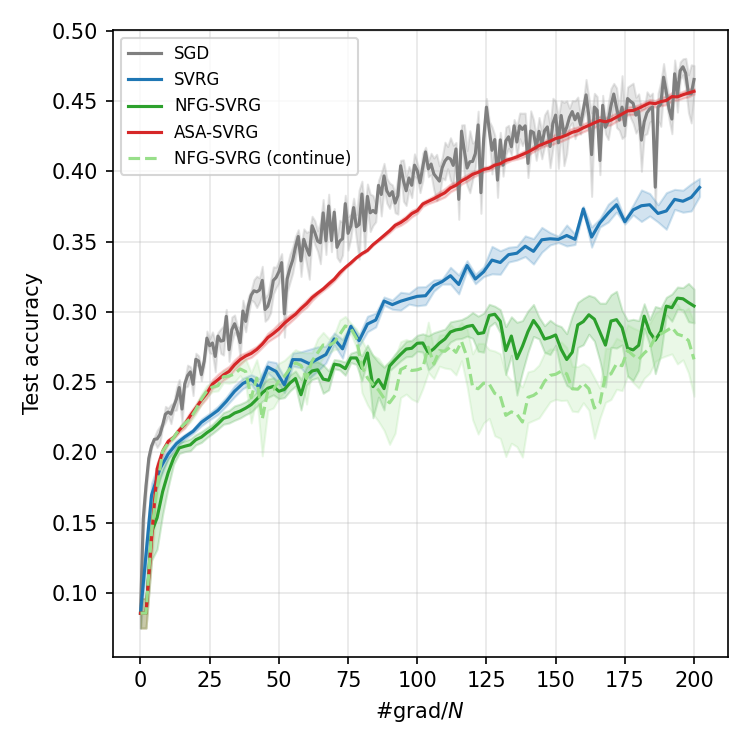

e3_check_grad_train_loss.png


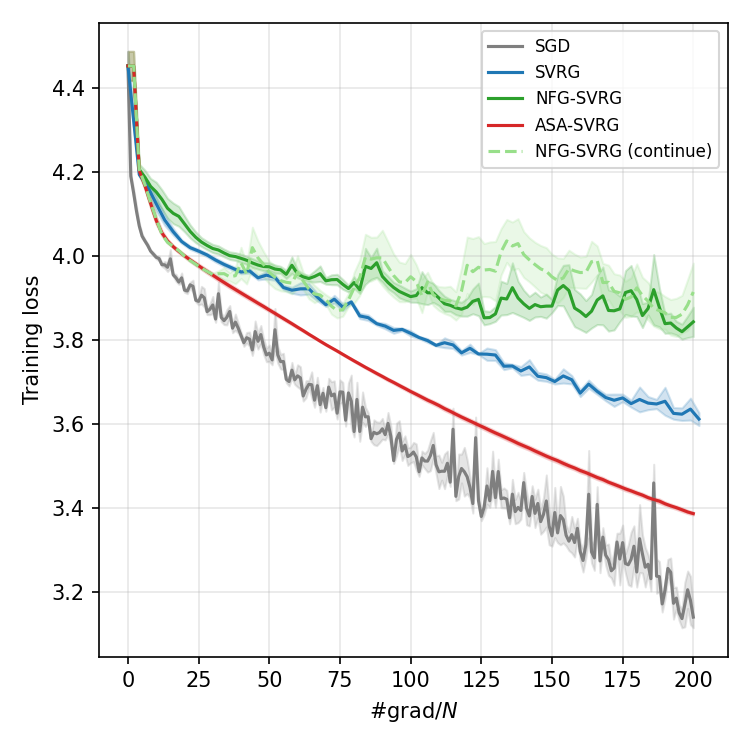

e3_check_walltime_test_accuracy.png


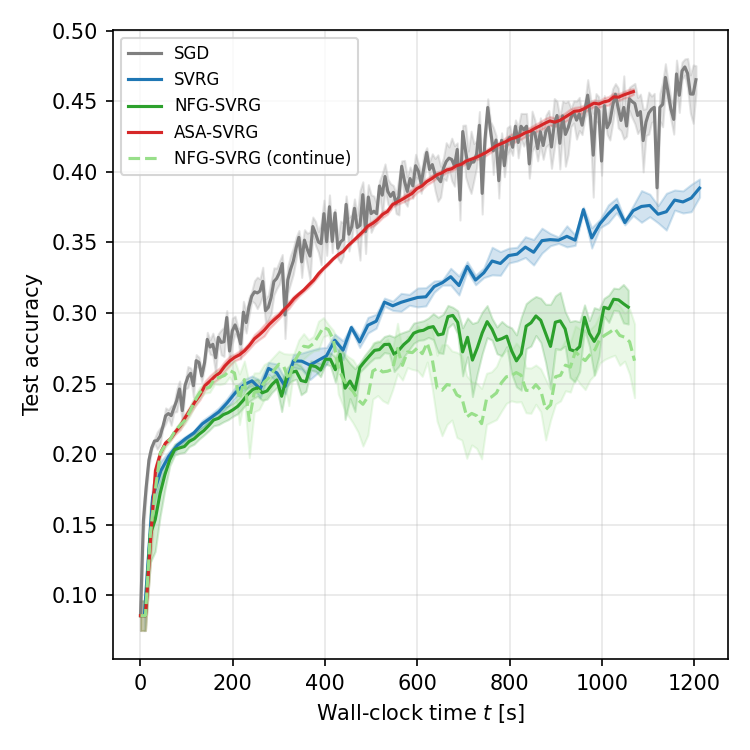

e3_check_walltime_train_loss.png


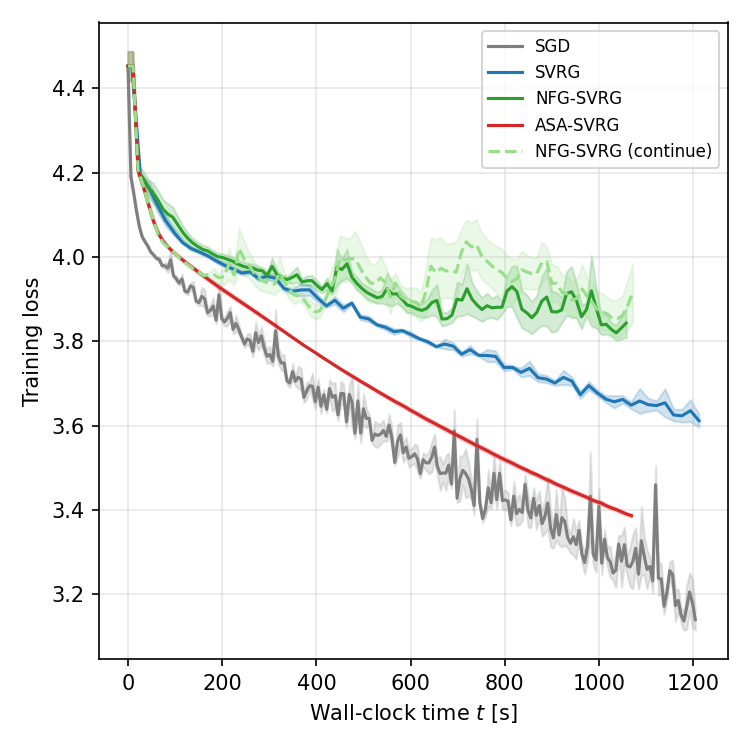

e3_grad_test_accuracy.png


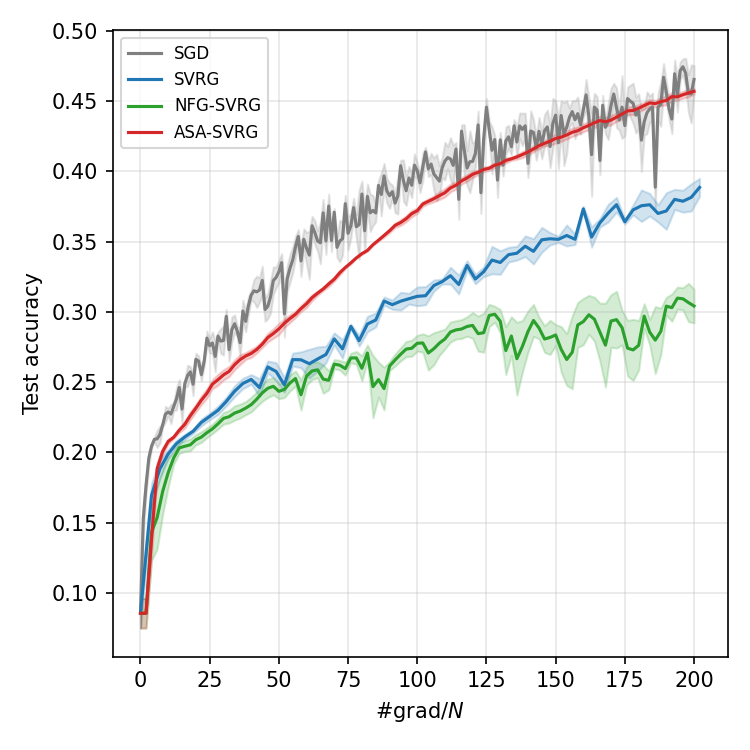

e3_grad_train_loss.png


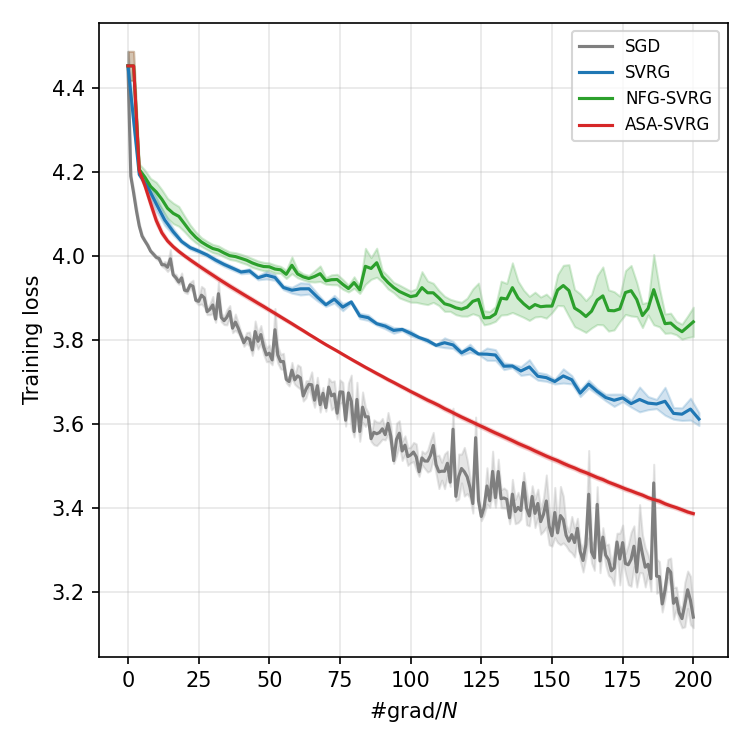

e3_walltime_test_accuracy.png


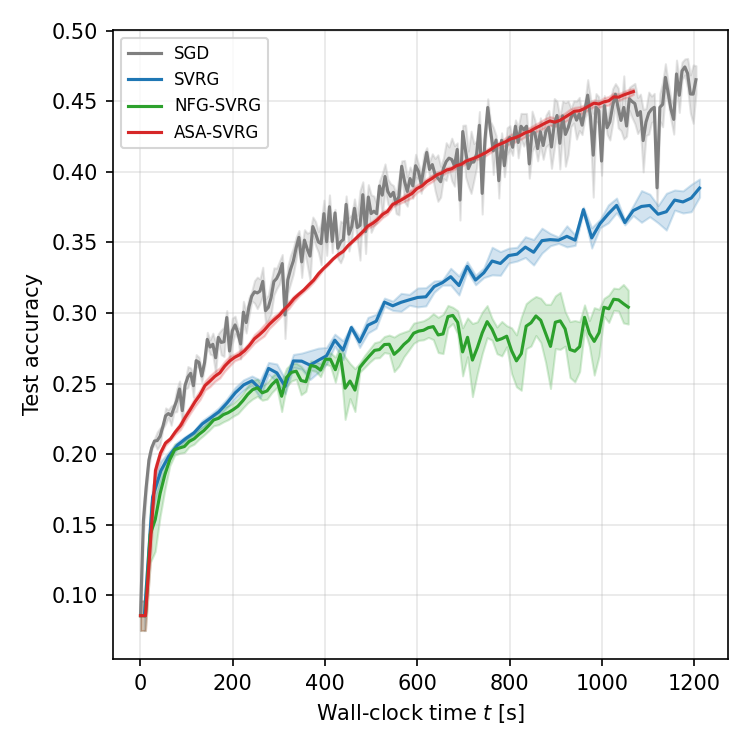

e3_walltime_train_loss.png


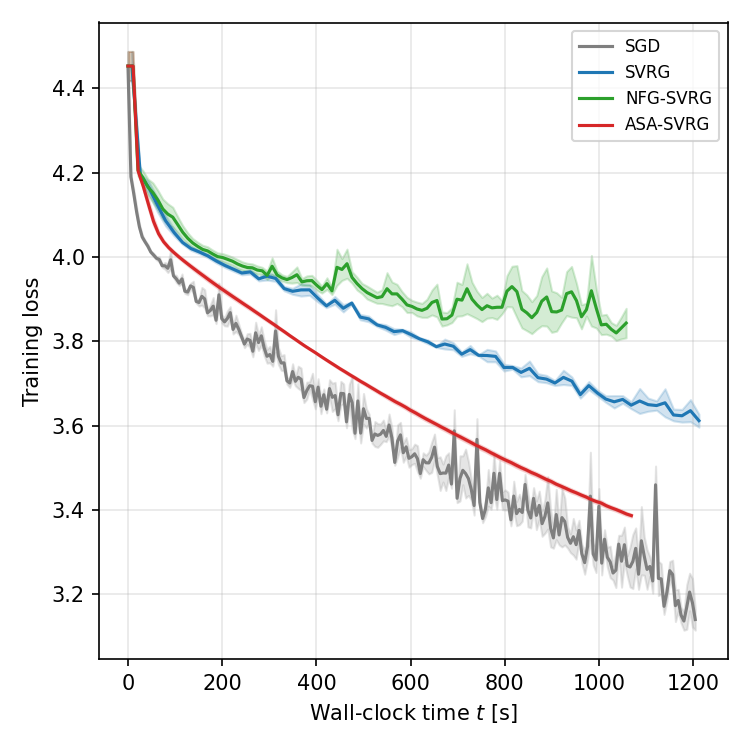

In [3]:
from IPython.display import Image

for name in sorted(os.listdir(a.FIGURE_DIR)):
    if name.endswith(".png"):
        print(name)
        display(Image(os.path.join(a.FIGURE_DIR, name)))